In [1]:
import os
import pandas as pd
import numpy as np
from tqdm import tqdm
from src.util import *
from src.models.model import *
from src.config import *
from src.preprocess import *
from src.generate_operating_condition import *
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split

In [2]:
%load_ext tensorboard 

In [4]:
%tensorboard --logdir logs/fit --host localhost --port 8889

## 1. 데이터 구성 

#### 데이터로드

In [5]:
input_path="./dataset/processed/input/"
output_path="./dataset/processed/output/"
boundary_condition_path=input_path+"boundary/"
operating_condition_path=input_path+"operating/"

In [6]:
boundary_data=np.load(boundary_condition_path+'boundary_condition.npy')
operating_data=np.load(operating_condition_path+'operating_condition.npy')
label_data=np.load(output_path+'label.npy')

boundary_data.shape, operating_data.shape, label_data.shape

((600000,), (20, 4), (20, 600000))

In [7]:
simul_config = simulaion_config()
x_dim = simul_config.x_dim
y_dim = simul_config.y_dim
z_dim = simul_config.z_dim

#### 데이터 전처리

In [8]:
# 공간정보 데이터
boundary_data = np.array([boundary_data]*20)
boundary_data_temp = boundary_data.copy()
boundary_data = []
for i in boundary_data_temp:
    i = i.reshape(x_dim,y_dim,z_dim,1)
    boundary_data.append(i)
boundary_data = np.array(boundary_data).astype('float32')
boundary_data.shape

(20, 150, 100, 40, 1)

In [9]:
# 운전정보 데이터
char2idx,idx2char=generate_operating_condition()
operating_data=driving_division(operating_data,idx2char)
driving_config=driving_condition_max_value_config(operating_data)
operating_data=driving_scaling(operating_data,driving_config)

special_token=[]
special_value=[]
for i in range(len(operating_data)):
    special_token.append(operating_data[:,0][i])
    special_value.append(operating_data[:,1][i])
special_token=np.array(special_token)
special_value=np.array(special_value)
special_token.shape,special_value.shape

((20, 2), (20, 2))

In [10]:
# 레이블 데이터 스케일링
max_label = np.max(label_data)
min_label = np.min(label_data)

label_data = (label_data-min_label)/(max_label-min_label)
print(np.max(label_data), np.min(label_data))

# 레이블 데이터 구성
label_data_temp = label_data.copy()
label_data = []
for i in label_data_temp:
    i = i.reshape(x_dim,y_dim,z_dim,1)
    label_data.append(i)
label_data = np.array(label_data).astype('float32')
label_data.shape


1.0 0.0


(20, 150, 100, 40, 1)

#### 데이터 분할

In [11]:
train_ratio = 0.75
valid_ratio = 0.15
test_ratio = 0.10
first_split_size=1-train_ratio
second_split_size=test_ratio/(test_ratio+valid_ratio)

# 데이터분할
cnn_train, cnn_tv, label_train, label_tv = train_test_split(boundary_data, label_data, test_size=first_split_size, random_state=42)
cnn_val, cnn_test, label_val, label_test = train_test_split(cnn_tv, label_tv, test_size=second_split_size, random_state=42)
spe_tok_train, spe_tok_tv, val_tok_train, val_tok_tv = train_test_split(special_token, special_value, test_size=first_split_size, random_state=42)
spe_tok_val, spe_tok_test, val_tok_val, val_tok_test = train_test_split(spe_tok_tv, val_tok_tv, test_size=second_split_size, random_state=42)

# 시뮬레이션 정보 분할
simulation_info = pd.read_csv("src/simulation_info.csv")
simulation_info = simulation_info['inlet_velocity'].values
simulation_train,simulation_tv = train_test_split(simulation_info,test_size=first_split_size, random_state=42)
simulation_val,simulation_test = train_test_split(simulation_tv,test_size=second_split_size, random_state=42)

In [12]:
X_train = [cnn_train, spe_tok_train, val_tok_train]
X_test = [cnn_test, spe_tok_test, val_tok_test]
X_val = [cnn_val, spe_tok_val, val_tok_val]
Y_train = label_train
Y_test = label_test
Y_val = label_val
print("X_train ",X_train[0].shape)
print("X_val ",X_val[0].shape)
print("X_test ",X_test[0].shape)
print("Y_train ",Y_train.shape)
print("Y_val ",Y_val.shape)
print("Y_test ",Y_test.shape,'\n')

X_train  (15, 150, 100, 40, 1)
X_val  (3, 150, 100, 40, 1)
X_test  (2, 150, 100, 40, 1)
Y_train  (15, 150, 100, 40, 1)
Y_val  (3, 150, 100, 40, 1)
Y_test  (2, 150, 100, 40, 1) 



## 2. 모델 구성

#### 모델정의

In [13]:
model_config=get_transformer_config()

In [14]:
model=CFDUnet(model_config)

#### 모델 컴파일

In [15]:
initial_learning_rate = 1e-5

lr_schedule = keras.optimizers.schedules.ExponentialDecay(
    initial_learning_rate, decay_steps=100000, decay_rate=0.96, staircase=True
)

model.compile(
    loss=tf.keras.losses.MeanAbsoluteError(),
    optimizer=keras.optimizers.Adam(learning_rate=lr_schedule),
    metrics=["mae","mse"],
)

#### 모델 경로지정

In [16]:
# 모델 저장 경로정의
WEIGHT_PATH = 'checkpoints/'
model_name = 'transUnet/'
test_num = 4
TEST_DIR = 'TEST' + str(test_num) + '/'

# 경로지정
checkpoint_path = WEIGHT_PATH + model_name + TEST_DIR + "TEST" + str(test_num)
checkpoint_dir = os.path.dirname(checkpoint_path)

In [17]:
checkpoint_dir,checkpoint_path

('checkpoints/transUnet/TEST4', 'checkpoints/transUnet/TEST4/TEST4')

#### weight load

In [18]:
model.load_weights(checkpoint_path)

In [19]:
print(simulation_train)
print(simulation_val)
print(simulation_test)

[1.5  3.   1.   4.75 4.25 3.5  0.75 2.5  5.   1.25 3.25 2.   2.75 3.75
 1.75]
[4.   0.25 0.5 ]
[4.5  2.25]


In [21]:
data_path = "dataset/processed/csv/"
all_df = []
simulation_lst = []
filelst = os.listdir(data_path)
for i in (filelst):
    simulation_lst.append(re.sub(".csv", "",i.split("_")[2]))
    df = pd.read_csv(data_path+i)
    all_df.append(df)
print(simulation_lst)

['0.25', '0.5', '0.75', '1', '1.25', '1.5', '1.75', '2', '2.25', '2.5', '2.75', '3', '3.25', '3.5', '3.75', '4', '4.25', '4.5', '4.75', '5']


## 추론

In [22]:
train_pred = model.predict(X_train,batch_size=1)
val_pred = model.predict(X_val,batch_size=1)
test_pred = model.predict(X_test,batch_size=1)

In [24]:
train_pred.shape,val_pred.shape,test_pred.shape

((15, 150, 100, 40, 1), (3, 150, 100, 40, 1), (2, 150, 100, 40, 1))

In [111]:
# [레이블] 역스케일링
Y_train_copy = Y_train.copy()
Y_test_copy = Y_test.copy()
Y_val_copy = Y_val.copy()

for i in range(len(Y_train_copy)):
    Y_train_copy[i]=(Y_train_copy[i]*(max_label-min_label)+min_label)
for i in range(len(Y_test_copy)):
    Y_test_copy[i]=(Y_test_copy[i]*(max_label-min_label)+min_label)
for i in range(len(Y_val_copy)):
    Y_val_copy[i]=(Y_val_copy[i]*(max_label-min_label)+min_label)

# [예측] 역스케일링
Y_train_pred = train_pred.copy()
Y_val_pred = val_pred.copy()
Y_test_pred = test_pred.copy()
for i in range(len(Y_train_pred)):
    Y_train_pred[i]=(Y_train_pred[i]*(max_label-min_label)+min_label)
for i in range(len(Y_val_pred)):
    Y_val_pred[i]=(Y_val_pred[i]*(max_label-min_label)+min_label)
for i in range(len(Y_test_pred)):
    Y_test_pred[i]=(Y_test_pred[i]*(max_label-min_label)+min_label)

In [118]:
print(simulation_train)
print(simulation_val)
print(simulation_test)

[1.5  3.   1.   4.75 4.25 3.5  0.75 2.5  5.   1.25 3.25 2.   2.75 3.75
 1.75]
[4.   0.25 0.5 ]
[4.5  2.25]


In [112]:
pred = Y_train_pred[0].reshape(x_dim*y_dim*z_dim)
new_df = all_df[0].copy()
new_df["prediction"] = pred
new_df["vel_mag"] = Y_train_copy[0].reshape(150*100*40)

-0.37886926531791687 2.453023910522461


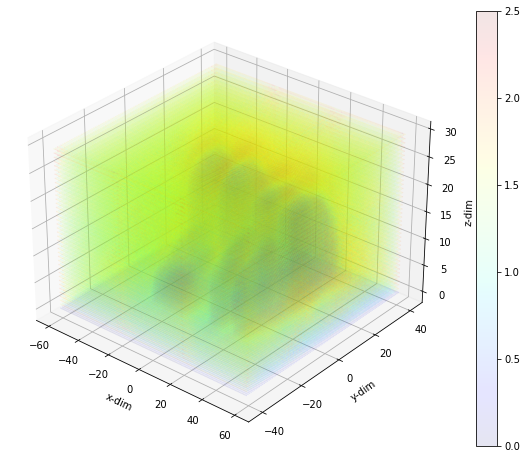

In [113]:
# plotting (예측)
min_vel_mag = min(new_df["prediction"])
max_vel_mag = max(new_df["prediction"])
print(min_vel_mag,max_vel_mag)
setting_lst = [12,8,0.2,0.1,0,2.5,30,310]
plotting(new_df,new_df["prediction"],setting_lst)

0.0 2.4824697971343994


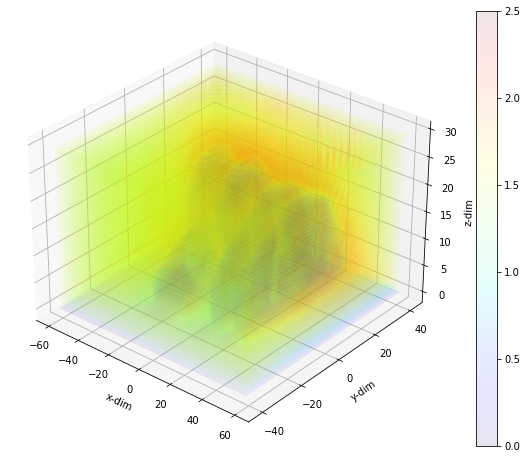

In [114]:
# plotting (레이블)
min_vel_mag = min(new_df["vel_mag"])
max_vel_mag = max(new_df["vel_mag"])
print(min_vel_mag,max_vel_mag)
setting_lst = [12,8,0.2,0.1,0,2.5,30,310]
plotting(new_df,new_df["vel_mag"],setting_lst)

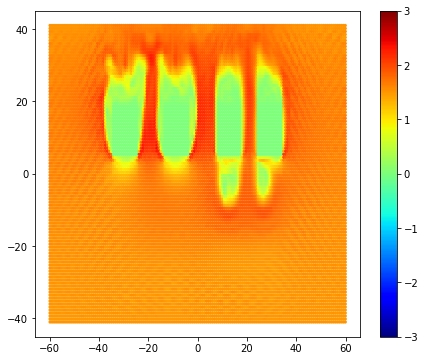

In [131]:
## 단면으로 결과확인 (z 고정)
position_z = 20
default_z = sorted(list(set(new_df["z"]))) # 고정될 z값 (xy 단면을 보기위해)
condition_z = new_df["z"]==default_z[position_z] # z 조건 정의
x = new_df[condition_z]["x"]
y = new_df[condition_z]["y"]
plot_data = new_df[condition_z]["vel_mag"]

plt.figure(figsize=[16,6])
plt.subplot(1,2,1)
plt.scatter(x,y,c=plot_data, marker="o", s=5, cmap='jet', label="Label", vmin=-3, vmax=3)
plt.colorbar()

-1.305875301361084 1.2949581146240234


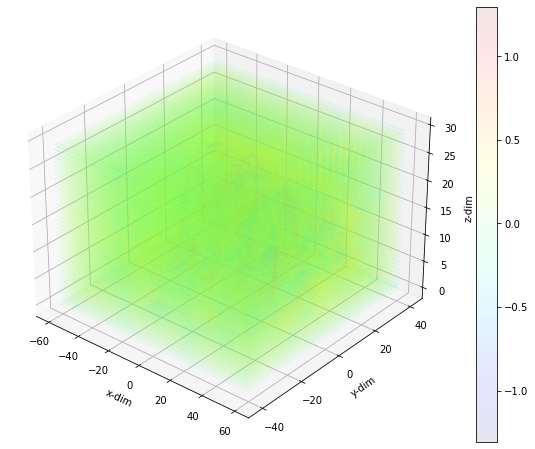

In [115]:
# plotting
diff = new_df["vel_mag"]-new_df["prediction"]
new_df["diff"] = diff
min_vel_mag = min(diff)
max_vel_mag = max(diff)
print(min_vel_mag,max_vel_mag)
setting_lst = [12,8,0.2,0.1,min_vel_mag,max_vel_mag,30,310]
plotting(new_df,new_df["diff"],setting_lst)

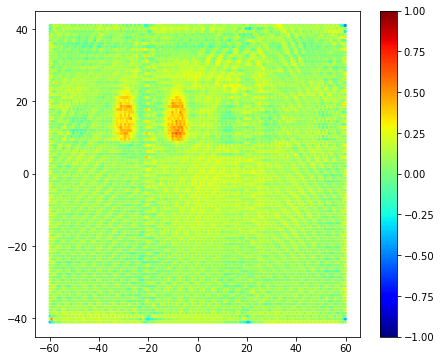

In [128]:
## 단면으로 결과확인 (z 고정)
position_z = 30
default_z = sorted(list(set(new_df["z"]))) # 고정될 z값 (xy 단면을 보기위해)
condition_z = new_df["z"]==default_z[position_z] # z 조건 정의
x = new_df[condition_z]["x"]
y = new_df[condition_z]["y"]
plot_data = new_df[condition_z]["diff"]

plt.figure(figsize=[16,6])
plt.subplot(1,2,1)
plt.scatter(x,y,c=plot_data, marker="o", s=5, cmap='jet', label="Label", vmin=-1, vmax=1)
plt.colorbar()

In [117]:
# Pyvista Plot
opt_list=[0.01,1,10,0.4,0,1]
plot_data = new_df["diff"].values
plot=plot_data.reshape(x_dim*y_dim*z_dim)
array_list=[new_df["x"].values,new_df["y"].values,new_df["z"].values]
pyvista_plot(plot,opt_list,array_list)

In [121]:
from sklearn.metrics import r2_score
import seaborn as sns
from sklearn.metrics import mean_squared_error

In [122]:
r2_scores = []
rmse_lst = []
for num in range(len(Y_train_copy)):
    r2_label = Y_train_copy[num].reshape(x_dim*y_dim*z_dim)
    r2_pred = Y_train_pred[num].reshape(x_dim*y_dim*z_dim)
    r2_scores.append(r2_score(r2_label,r2_pred))
    rmse = np.sqrt(mean_squared_error(r2_label,r2_pred))
    rmse_lst.append(rmse)
print(f" R2 score 평균점수 : {np.average(r2_scores)}")
print(f" RMSE 평균 : {np.average(rmse_lst)}")

 R2 score 평균점수 : 0.8576141757251209
 RMSE 평균 : 0.2796420753002167


<Figure size 864x720 with 0 Axes>

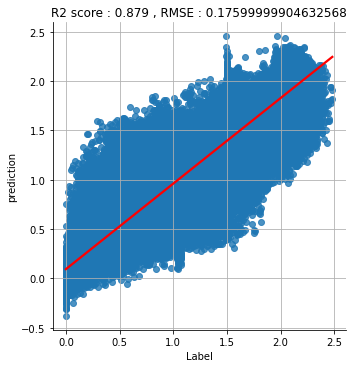

In [124]:
y_label = Y_train_copy[0].reshape(x_dim*y_dim*z_dim)
y_pre = Y_train_pred[0].reshape(x_dim*y_dim*z_dim)

reg_df = pd.DataFrame({"label":y_label,"prediction":y_pre})
r2score = np.round(r2_score(y_label,y_pre),3)
rmse = np.round(np.sqrt(mean_squared_error(y_label,y_pre)),3)

plt.figure(figsize=[12,10])
ax = sns.lmplot(x="label", y="prediction", data=reg_df, line_kws = {'color' : 'red'})
plt.xlabel("Label")
plt.ylabel("prediction")
plt.title(f"R2 score : {r2score} , RMSE : {rmse}")
plt.grid()